# Recovering $D_x$ from a steady droplet size distribution

**The simplest parameter-estimation experiment:** steady state, no noise, the whole distribution observed, and a single unknown constant $D_x$.

The plan:

1. Solve the steady Fokker–Planck equation for the droplet size distribution $N(x)$, where $x = r^2$.
2. Pick a "true" $D_x$, solve once, and treat that solution as the observed data.
3. Define a loss that measures the mismatch between the model and the data.
4. Compute the gradient of the loss with the **adjoint method**.
5. Minimize the loss with gradient descent, starting from many different guesses, for several true values of $D_x$.

Units throughout: droplet sizes in µm, time in s, concentrations in cm⁻³. So $x$ is in µm², $N$ in cm⁻³ µm⁻², $D_x$ in µm⁴/s.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import splu

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## 1. Physical parameters

A droplet's squared radius grows at the rate

$$\frac{dx}{dt} = A(x) = a\,\bigl(s - s_{\rm eq}(r)\bigr), \qquad s_{\rm eq}(r) = \frac{A_k}{r} - \frac{B_k}{r^3}.$$

- $s$ is the chamber's supersaturation: how far the air is above 100% humidity. Here $s = 0.09\%$.
- $a$ is a growth coefficient set by temperature and pressure.
- $s_{\rm eq}(r)$ is the supersaturation at which a droplet of radius $r$ neither grows nor shrinks (Köhler theory). It only matters for tiny droplets, around 1 µm or smaller.

Droplets also fall out of the chamber at a rate proportional to $x$: bigger droplets fall faster.

In [2]:
# Thermodynamic state
T = 288.0          # temperature (K)
p = 1000e2         # pressure (Pa)

def saturation_vapor_pressure(T):
    '''Saturation vapor pressure over water (Pa).'''
    return 100.0 * 10.0 ** (23.832241 - 5.02808 * np.log10(T)
                            - 1.3816e-7 * 10.0 ** (11.344 - 0.0303998 * T)
                            + 8.1328e-3 * 10.0 ** (3.49149 - 1302.8844 / T)
                            - 2949.076 / T)

def growth_coefficient(T, p):
    '''xi in r dr/dt = xi * s, in um^2/s.'''
    T0, Lv, Rv, rho_w = 273.15, 2.5e6, 461.5, 1000.0
    K = 7.7e-5 * (T - T0) + 0.02399                        # thermal conductivity of air
    Dv = (1.57e-7 * (T - T0) + 2.211e-5) * 1e5 / p           # diffusivity of water vapor
    denom = rho_w * ((Lv / (Rv * T)) * Lv / (K * T) + Rv * T / (saturation_vapor_pressure(T) * Dv))
    return 1e12 / denom

a = 2 * growth_coefficient(T, p)     # dx/dt = a * s   (um^2/s)
s = 0.0009                           # supersaturation (0.09%)

# Kohler equilibrium curve for a salt (NaCl) particle of dry radius 0.065 um
r_dry = 0.065                                             # um
sigma_w, M_w, R, rho_w = 0.075, 18e-3, 8.314, 1000.0
rho_s, M_s, nu_s = 2160.0, 58.5e-3, 2.0
m_s = (4 / 3) * np.pi * (r_dry * 1e-6) ** 3 * rho_s        # kg of salt
A_k = 2 * sigma_w * M_w / (rho_w * R * T) * 1e6                    # um
B_k = 3 * nu_s * m_s * M_w / (4 * np.pi * rho_w * M_s) * 1e18      # um^3

# Settling: fall speed v = C_stk * r^2, removal rate = v / h
rho_air = p / (287.0 * T)
C_stk = 2 * (rho_w - rho_air) * 9.81 / (9 * 1.8e-5)   # 1/(m s)
h = 1.0                                               # chamber height (m)
k_settle = C_stk * 1e-12 / h                          # removal rate = k_settle * x  (1/s per um^2)

F_in = 100.0       # droplets injected per cm^3 per second

print(f"a = {a:.1f} um^2/s,  A_k = {A_k:.3e} um,  B_k = {B_k:.3e} um^3")
print(f"critical radius = {np.sqrt(3*B_k/A_k):.3f} um,  critical supersaturation = {100*np.sqrt(4*A_k**3/(27*B_k)):.4f} %")

a = 205.8 um^2/s,  A_k = 1.128e-03 um,  B_k = 3.650e-04 um^3
critical radius = 0.985 um,  critical supersaturation = 0.0763 %


## 2. The grid, the drift, and the settling rate

We split the size axis $x \in [x_{\min}, x_{\max}]$ into $n$ equal cells. The unknown $N_i$ is the average of $N(x)$ over cell $i$, so $N_i\,\Delta x$ is the concentration (cm⁻³) of droplets whose $x$ lies in that cell.

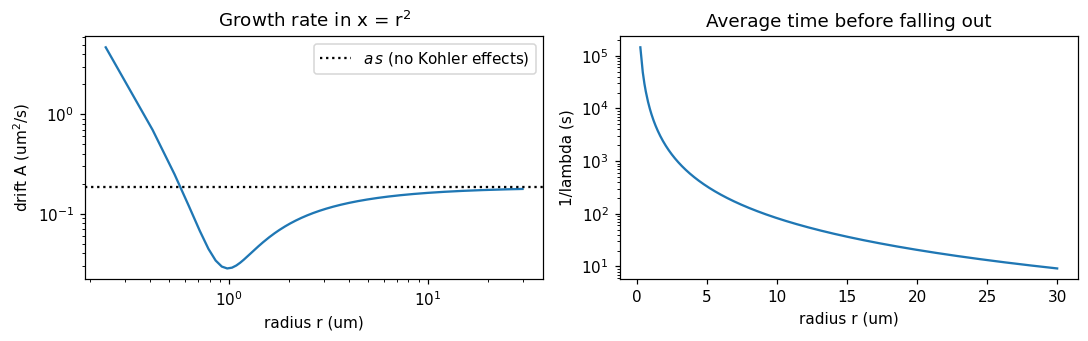

8000 cells, dx = 0.1125 um^2


In [3]:
class Grid:
    def __init__(self, n_cells=8000, r_min=r_dry / 2, r_max=30.0):
        self.n = n_cells
        self.faces = np.linspace(r_min ** 2, r_max ** 2, n_cells + 1)   # cell edges in x (um^2)
        self.x = 0.5 * (self.faces[:-1] + self.faces[1:])                # cell centers
        self.dx = self.faces[1] - self.faces[0]
        self.r = np.sqrt(self.x)                                         # radius at cell centers (um)

grid = Grid()
drift = a * (s - (A_k / grid.r - B_k / grid.r ** 3))    # A(x) at cell centers (um^2/s)
settling = k_settle * grid.x                             # lambda(x) (1/s)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].loglog(grid.r, drift)
ax[0].axhline(a * s, color="k", ls=":", label="$a\\,s$ (no Kohler effects)")
ax[0].set(xlabel="radius r (um)", ylabel="drift A (um$^2$/s)", title="Growth rate in x = r$^2$"); ax[0].legend()
ax[1].plot(grid.r, 1 / settling); ax[1].set_yscale("log")
ax[1].set(xlabel="radius r (um)", ylabel="1/lambda (s)", title="Average time before falling out")
plt.tight_layout(); plt.show()
print(f"{grid.n} cells, dx = {grid.dx:.4f} um^2")

## 3. The finite-volume solver

In each cell, droplets flowing in across the left edge, minus droplets flowing out across the right edge, minus droplets falling out, must balance:

$$F_{i+1/2} - F_{i-1/2} + \lambda_i N_i\,\Delta x = 0 .$$

The flux across an edge uses the **Scharfetter–Gummel** formula,

$$F_{i+1/2} = \alpha_i N_i + \beta_i N_{i+1}, \qquad \alpha_i = \frac{D}{\Delta x}\,B(-\mathrm{Pe}_i), \quad \beta_i = -\frac{D}{\Delta x}\,B(\mathrm{Pe}_i), \quad \mathrm{Pe}_i = \frac{A_{i+1/2}\,\Delta x}{D},$$

with the Bernoulli function $B(z) = z/(e^z - 1)$. It behaves like ordinary diffusion when $|\mathrm{Pe}|$ is small and like "take the upstream value" when $|\mathrm{Pe}|$ is large, and it never produces negative concentrations.

Boundary conditions: $F_{\rm in}$ droplets per cm³ per second enter through the left edge, and nothing leaves through the right edge. Together these give a tridiagonal linear system $\mathsf{A}(D)\,\mathbf{N} = \mathbf{b}$.

In [4]:
def bernoulli(z):
    '''B(z) = z / (e^z - 1), evaluated without overflow or cancellation.'''
    z = np.asarray(z, float); out = np.empty_like(z)
    small = np.abs(z) < 0.1; zs = z[small]
    out[small] = 1 - zs / 2 + zs ** 2 / 12 - zs ** 4 / 720 + zs ** 6 / 30240
    pos = (~small) & (z > 0); out[pos] = z[pos] * np.exp(-z[pos]) / (-np.expm1(-z[pos]))
    neg = (~small) & (z < 0); out[neg] = z[neg] / np.expm1(z[neg])
    return out

def bernoulli_prime(z):
    '''dB/dz.'''
    z = np.asarray(z, float); out = np.empty_like(z)
    small = np.abs(z) < 0.1; zs = z[small]
    out[small] = -0.5 + zs / 6 - zs ** 3 / 180 + zs ** 5 / 5040
    pos = (~small) & (z > 0); em = np.exp(-z[pos]); d = -np.expm1(-z[pos])
    out[pos] = em / d - z[pos] * em / d ** 2
    neg = (~small) & (z < 0); E = np.expm1(z[neg])
    out[neg] = 1 / E - z[neg] * (E + 1) / E ** 2
    return out

drift_face = 0.5 * (drift[:-1] + drift[1:])       # drift at the interior edges

def assemble(alpha, beta, diagonal):
    '''Tridiagonal matrix from edge coefficients. Row i: F_{i+1/2} - F_{i-1/2} + diagonal_i N_i.'''
    main = diagonal.copy()
    main[:-1] += alpha        # flux out through the right edge
    main[1:] -= beta          # flux in through the left edge
    return diags([-alpha, main, beta], [-1, 0, 1], format="csc")

def system_matrix(D):
    Pe = drift_face * grid.dx / D
    return assemble((D / grid.dx) * bernoulli(-Pe), -(D / grid.dx) * bernoulli(Pe), settling * grid.dx)

def system_matrix_dD(D):
    '''Derivative of the system matrix with respect to D (settling does not depend on D).'''
    Pe = drift_face * grid.dx / D
    d_alpha = (bernoulli(-Pe) + Pe * bernoulli_prime(-Pe)) / grid.dx
    d_beta = -(bernoulli(Pe) - Pe * bernoulli_prime(Pe)) / grid.dx
    return assemble(d_alpha, d_beta, np.zeros(grid.n))

b = np.zeros(grid.n); b[0] = F_in

def solve(D):
    '''Steady distribution N (cm^-3 um^-2) for diffusivity D (um^4/s), plus the LU factors of A.'''
    lu = splu(system_matrix(D))
    return lu.solve(b), lu

### What $D_x$ does to the distribution

Larger $D_x$ means stronger turbulent spreading: a broader distribution that reaches larger sizes. To compare shapes, we plot the distribution per unit **radius**, $2r\,N(r^2)$, normalized to area 1.

As a check, at steady state every droplet injected must eventually fall out, so $F_{\rm in} = \sum_i \lambda_i N_i\,\Delta x$.

D =   0.01:  total =    36279 cm^-3,  mean radius =  4.22 um,  settling out = 100.000000 (injected 100.0)
D =    0.1:  total =    34408 cm^-3,  mean radius =  4.38 um,  settling out = 100.000000 (injected 100.0)
D =      1:  total =    29946 cm^-3,  mean radius =  4.75 um,  settling out = 100.000000 (injected 100.0)
D =     10:  total =    20551 cm^-3,  mean radius =  5.74 um,  settling out = 100.000000 (injected 100.0)
D =    100:  total =    10869 cm^-3,  mean radius =  7.88 um,  settling out = 100.000000 (injected 100.0)


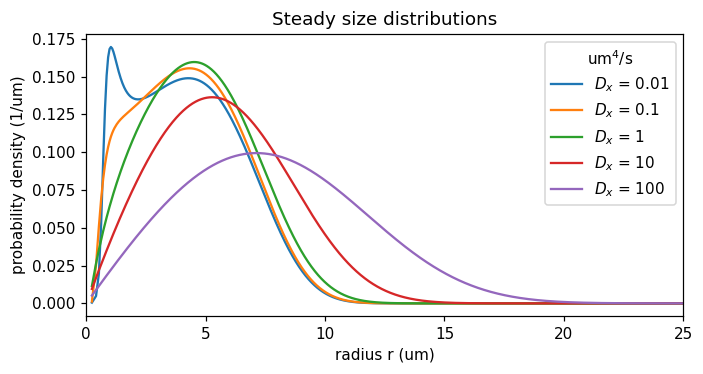

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for D in [0.01, 0.1, 1, 10, 100]:
    N, _ = solve(D)
    n_r = 2 * grid.r * N
    pdf = n_r / np.trapezoid(n_r, grid.r)
    mean_r = np.sum(grid.r * N) / np.sum(N)
    total = np.sum(N) * grid.dx
    balance = np.sum(settling * N) * grid.dx
    ax.plot(grid.r, pdf, label=f"$D_x$ = {D:g}")
    print(f"D = {D:6g}:  total = {total:8.0f} cm^-3,  mean radius = {mean_r:5.2f} um,  "
          f"settling out = {balance:.6f} (injected {F_in})")
ax.set(xlim=(0, 25), xlabel="radius r (um)", ylabel="probability density (1/um)",
       title="Steady size distributions")
ax.legend(title="um$^4$/s"); plt.tight_layout(); plt.show()

## 4. Synthetic data and the loss

Pick a true value, solve once, and call the result $\mathbf{N}^{\rm obs}$. The loss is half the squared relative mismatch:

$$\mathcal{J} = \frac12\,\frac{\sum_i (N_i - N_i^{\rm obs})^2}{\sum_i (N_i^{\rm obs})^2}.$$

We estimate $\ell = \ln D_x$ instead of $D_x$ itself. This keeps $D_x$ positive, and it treats "twice as big" and "half as big" as equally far away.

## 5. The adjoint gradient

Differentiating $\mathsf{A}\mathbf{N} = \mathbf{b}$ with respect to $D$ gives $\mathsf{A}\,\dfrac{d\mathbf{N}}{dD} = -\dfrac{d\mathsf{A}}{dD}\mathbf{N}$. Then

$$\frac{d\mathcal{J}}{dD} = \Bigl(\frac{\partial \mathcal{J}}{\partial \mathbf{N}}\Bigr)^{\!\top}\frac{d\mathbf{N}}{dD} = -\Bigl(\frac{\partial \mathcal{J}}{\partial \mathbf{N}}\Bigr)^{\!\top}\mathsf{A}^{-1}\frac{d\mathsf{A}}{dD}\mathbf{N}.$$

Define the **adjoint** $\boldsymbol\psi$ by one extra solve with the transposed matrix:

$$\mathsf{A}^{\top}\boldsymbol\psi = -\frac{\partial \mathcal{J}}{\partial \mathbf{N}}
\qquad\Longrightarrow\qquad
\frac{d\mathcal{J}}{dD} = \boldsymbol\psi^{\top}\,\frac{d\mathsf{A}}{dD}\,\mathbf{N},
\qquad \frac{d\mathcal{J}}{d\ell} = D\,\frac{d\mathcal{J}}{dD}.$$

The transposed solve reuses the LU factors from the forward solve.

In [6]:
def loss_and_gradient(ell, N_obs, return_fields=False):
    D = np.exp(ell)
    N, lu = solve(D)                                   # forward solve
    scale = np.sum(N_obs ** 2)
    residual = N - N_obs
    J = 0.5 * np.sum(residual ** 2) / scale            # loss
    dJ_dN = residual / scale
    psi = lu.solve(-dJ_dN, trans="T")                  # adjoint solve: A^T psi = -dJ/dN
    dJ_dD = psi @ (system_matrix_dD(D) @ N)            # gradient formula
    if return_fields:
        return J, D * dJ_dD, N, psi
    return J, D * dJ_dD

# Gradient check against a centered finite difference
D_true = 10.0
N_obs, _ = solve(D_true)
eps = 1e-5
rows = []
for D in [0.01, 1.0, 5.0, 30.0, 300.0]:
    ell = np.log(D)
    J, g = loss_and_gradient(ell, N_obs)
    g_fd = (loss_and_gradient(ell + eps, N_obs)[0] - loss_and_gradient(ell - eps, N_obs)[0]) / (2 * eps)
    rows.append(dict(D=D, loss=J, adjoint=g, finite_difference=g_fd, relative_difference=abs(g - g_fd) / abs(g_fd)))
print(f"True D_x = {D_true}.  Loss at the truth = {loss_and_gradient(np.log(D_true), N_obs)[0]:.1e}")
pd.DataFrame(rows)

True D_x = 10.0.  Loss at the truth = 4.8e-25


,D,loss,adjoint,finite_difference,relative_difference
0,0.01,1.538987,-0.155349,-0.155349,3.547795e-09
1,1.00,0.328753,-0.225946,-0.225946,1.312081e-08
2,5.00,0.034910,-0.101356,-0.101356,1.267747e-07
3,30.00,0.067683,0.106674,0.106674,2.346682e-07
4,300.00,0.327129,0.087641,0.087641,7.052201e-07


### The loss landscape

For one unknown we can simply look at the loss. It should have a single minimum at the true value.

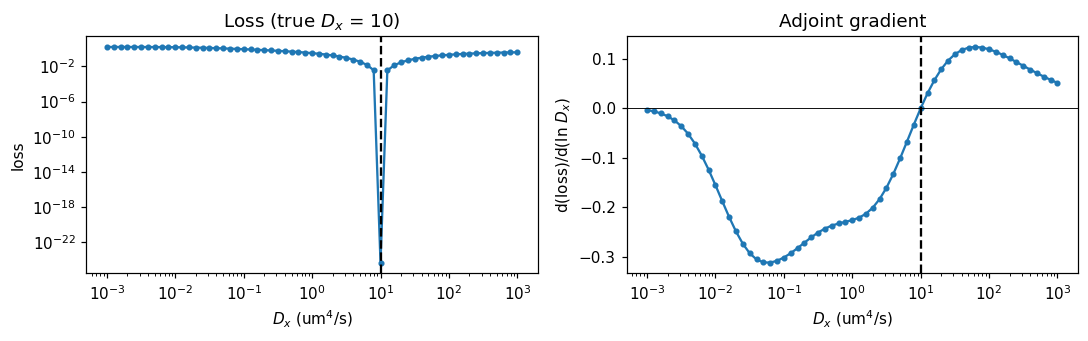

In [7]:
D_scan = np.logspace(-3, 3, 61)
scan = np.array([loss_and_gradient(np.log(D), N_obs) for D in D_scan])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].loglog(D_scan, scan[:, 0], ".-"); ax[0].axvline(D_true, color="k", ls="--")
ax[0].set(xlabel="$D_x$ (um$^4$/s)", ylabel="loss", title=f"Loss (true $D_x$ = {D_true:g})")
ax[1].semilogx(D_scan, scan[:, 1], ".-"); ax[1].axhline(0, color="k", lw=0.6); ax[1].axvline(D_true, color="k", ls="--")
ax[1].set(xlabel="$D_x$ (um$^4$/s)", ylabel="d(loss)/d(ln $D_x$)", title="Adjoint gradient")
plt.tight_layout(); plt.show()

### What the adjoint looks like

At a wrong guess ($D_x = 20$), the distribution is too spread out, so the model has too few droplets at small and middle sizes. The adjoint $\psi_i$ tells us how the loss would change if we added droplets in cell $i$: adding a small source $\delta b_i$ changes the loss by $\delta\mathcal{J} = -\psi_i\,\delta b_i$. Here $\psi$ is positive exactly where the model is short of droplets, because adding droplets there would lower the loss.

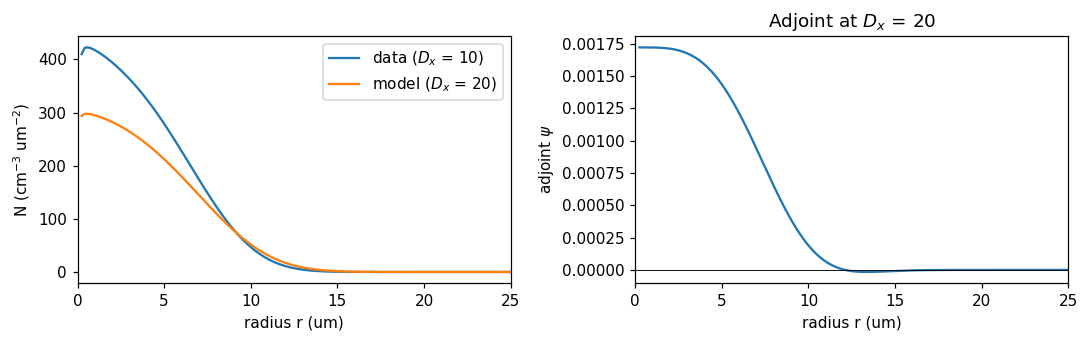

In [8]:
J, g, N20, psi20 = loss_and_gradient(np.log(20.0), N_obs, return_fields=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(grid.r, N_obs, label="data ($D_x$ = 10)"); ax[0].plot(grid.r, N20, label="model ($D_x$ = 20)")
ax[0].set(xlim=(0, 25), xlabel="radius r (um)", ylabel="N (cm$^{-3}$ um$^{-2}$)"); ax[0].legend()
ax[1].plot(grid.r, psi20); ax[1].axhline(0, color="k", lw=0.6)
ax[1].set(xlim=(0, 25), xlabel="radius r (um)", ylabel="adjoint $\\psi$", title="Adjoint at $D_x$ = 20")
plt.tight_layout(); plt.show()

## 6. The optimizer: gradient descent with a line search

Each iteration moves $\ell$ downhill, $\ell \leftarrow \ell - \alpha\,g$, where $g = d\mathcal{J}/d\ell$. The step size $\alpha$ is chosen by three simple rules:

1. **Guess** $\alpha$ from the last two iterations, using the secant estimate of the curvature: $\alpha = \Delta\ell / \Delta g$. If that estimate isn't positive, double the previous step instead.
2. **Cap** the move so $\ell$ changes by at most 1 per iteration, i.e. $D_x$ changes by at most a factor $e \approx 2.7$.
3. **Backtrack:** halve $\alpha$ until the loss decreases enough, $\mathcal{J}_{\rm new} \le \mathcal{J} + c\,g\,\Delta\ell$ with $c = 10^{-4}$.

Stop when $|g| < 10^{-10}$.

start 0.1  ->  estimate 10.0000000000  in 10 iterations, final loss 2.7e-25


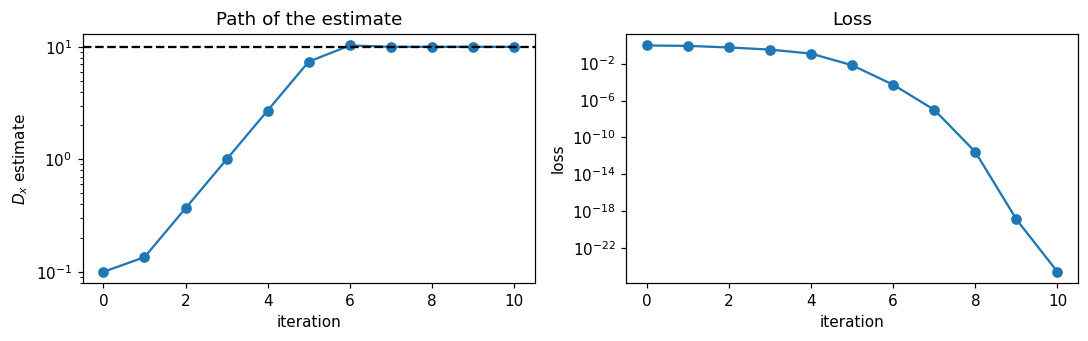

In [9]:
def gradient_descent(f, ell0, step0=1.0, max_move=1.0, tol=1e-10, max_iter=300, c=1e-4):
    '''Minimize f(ell) -> (loss, gradient). Returns the final ell and the history [(ell, loss, grad), ...].'''
    ell = ell0
    J, g = f(ell)
    step = step0
    history = [(ell, J, g)]
    for _ in range(max_iter):
        if abs(g) < tol:
            break
        while True:                                   # backtracking line search
            move = -step * g
            if abs(move) > max_move:
                move = np.sign(move) * max_move
            J_new, g_new = f(ell + move)
            if J_new <= J + c * g * move:
                break
            step *= 0.5
        dg = g_new - g
        step = move / dg if move * dg > 0 else 2 * step   # secant estimate for the next step
        ell, J, g = ell + move, J_new, g_new
        history.append((ell, J, g))
    return ell, np.array(history)

f = lambda ell: loss_and_gradient(ell, N_obs)
ell_hat, hist = gradient_descent(f, np.log(0.1))
print(f"start 0.1  ->  estimate {np.exp(ell_hat):.10f}  in {len(hist) - 1} iterations, final loss {hist[-1, 1]:.1e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(np.exp(hist[:, 0]), "o-"); ax[0].axhline(D_true, color="k", ls="--")
ax[0].set(xlabel="iteration", ylabel="$D_x$ estimate", yscale="log", title="Path of the estimate")
ax[1].semilogy(hist[:, 1], "o-"); ax[1].set(xlabel="iteration", ylabel="loss", title="Loss")
plt.tight_layout(); plt.show()

## 7. The experiment: many true values, many starting guesses

For each true $D_x \in \{0.01, 0.1, 1, 10, 100\}$ µm⁴/s, generate data and run the optimizer from starting guesses spanning six orders of magnitude, $10^{-3}$ to $10^{3}$.

In [10]:
true_values = [0.01, 0.1, 1.0, 10.0, 100.0]
starting_guesses = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1e3]

results, paths = [], {}
for D_true in true_values:
    N_obs, _ = solve(D_true)
    f = lambda ell: loss_and_gradient(ell, N_obs)
    for D0 in starting_guesses:
        ell_hat, hist = gradient_descent(f, np.log(D0))
        D_hat = np.exp(ell_hat)
        paths[(D_true, D0)] = np.exp(hist[:, 0])
        results.append(dict(true_D=D_true, start=D0, estimate=D_hat,
                            relative_error=abs(D_hat / D_true - 1),
                            iterations=len(hist) - 1, final_loss=hist[-1, 1]))
results = pd.DataFrame(results)
print(f"All recovered to relative error < 1e-6: {bool((results.relative_error < 1e-6).all())}")
print(f"Largest relative error: {results.relative_error.max():.1e},  most iterations: {results.iterations.max()}")
results.pivot(index="true_D", columns="start", values="iterations")

All recovered to relative error < 1e-6: True
Largest relative error: 5.4e-09,  most iterations: 21


start,0.001,0.010,0.100,1.000,10.000,100.000,1000.000
true_D,,,,,,,
0.01,19,0,8,11,13,18,21
0.10,18,11,0,7,10,14,18
1.00,19,12,8,0,8,12,16
10.00,20,13,10,7,0,10,13
100.00,21,16,13,11,9,0,11


In [11]:
results.pivot(index="true_D", columns="start", values="relative_error").style.format("{:.1e}")

start,0.001000,0.010000,0.100000,1.000000,10.000000,100.000000,1000.000000
true_D,,,,,,,
0.010000,4.0e-10,4.4e-16,5.4e-09,2.0e-11,1.3e-10,3.7e-13,1.5e-09
0.100000,2.3e-13,3.5e-13,2.2e-16,5.5e-10,2.0e-13,2.1e-12,2.6e-13
1.000000,4.5e-10,1.8e-12,8.3e-13,0.0e+00,2.7e-12,1.0e-11,2.4e-12
10.000000,1.1e-11,4.9e-12,5.0e-14,3.1e-13,2.2e-16,8.6e-13,3.1e-13
100.000000,2.3e-11,9.0e-13,4.9e-12,2.7e-13,3.6e-12,4.4e-16,6.4e-12


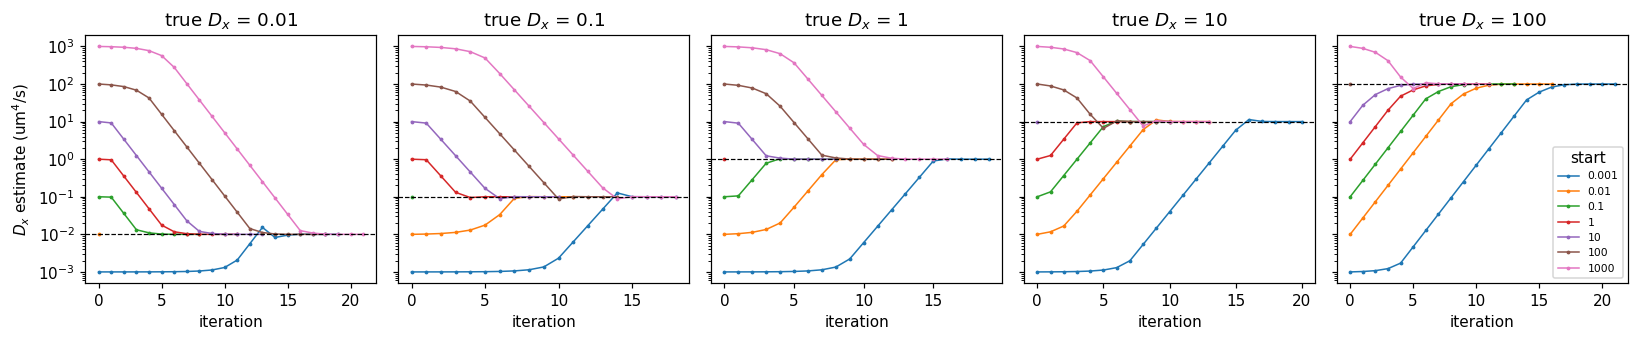

In [12]:
fig, axes = plt.subplots(1, len(true_values), figsize=(15, 3.2), sharey=True)
for ax, D_true in zip(axes, true_values):
    for D0 in starting_guesses:
        ax.plot(paths[(D_true, D0)], ".-", lw=1, ms=3, label=f"{D0:g}")
    ax.axhline(D_true, color="k", ls="--", lw=0.8)
    ax.set(yscale="log", xlabel="iteration", title=f"true $D_x$ = {D_true:g}")
axes[0].set_ylabel("$D_x$ estimate (um$^4$/s)")
axes[-1].legend(title="start", fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 8. A limit: starting guesses that are too small

If the starting guess is tiny, turbulent spreading is negligible next to the numerical spreading the grid itself introduces. The computed distribution then barely changes with $D_x$, so the gradient is essentially zero and the optimizer cannot move, even though the loss is far from zero. The threshold depends on the grid: finer grids push it lower.

In [13]:
N_obs, _ = solve(10.0)
for D0 in [1e-3, 1e-4, 1e-5]:
    J, g = loss_and_gradient(np.log(D0), N_obs)
    print(f"start {D0:g}: loss = {J:.3f}, gradient = {g:.1e}")

start 0.001: loss = 1.657, gradient = -3.4e-03
start 0.0001: loss = 1.658, gradient = -3.1e-15
start 1e-05: loss = 1.658, gradient = 4.9e-138


## Summary

- The adjoint gradient matches finite differences, and the loss is zero (to roundoff) at the true value.
- Gradient descent recovers every true $D_x$ from 0.01 to 100 µm⁴/s, from every starting guess between $10^{-3}$ and $10^{3}$, to near machine precision in about 20 iterations or fewer.
- Starting guesses far below the grid's numerical-diffusion level ($\lesssim 10^{-4}$ µm⁴/s on this grid) have no usable gradient, so a coarse scan of the loss is a good first step.

This experiment deliberately uses the same model and grid for the data and the fit, and has no noise. The next steps add those back one at a time.